# HW4: Full Fine-Tuning и LoRA

Сравниваются полное дообучение и LoRA для `Qwen/Qwen2.5-1.5B-Instruct` на классификации новостей AG News.
После Full FT accuracy на тесте составила 92.80%, после базовой LoRA — 91.92%.
Лучший LoRA-вариант по validation, `lora_all_linear`, получил 93.82% на тесте:
качество выше Full FT, но обучение медленнее.
У исходной модели на том же промпте получилось 30.25%.

Для всех запусков зафиксированы одни и те же 20 000 обучающих примеров, 2 000 validation и 7 600 test.
Дополнительно проведены четыре абляции LoRA: по одному изменяются `r`, `alpha`, `dropout` и `target_modules`.
Отчёт построен по сохранённым метрикам и предсказаниям; код запуска находится в `experiment.py`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

root = Path.cwd()
out = root / "outputs"
names = ["base", "full_ft", "lora_base", "lora_r64", "lora_alpha64", "lora_dropout15", "lora_all_linear"]
scores = {name: json.loads((out / name / "summary.json").read_text()) for name in names}
manifest = json.loads((out / "data_manifest.json").read_text())
classes = ["World", "Sports", "Business", "Sci/Tech"]
pd.set_option("display.max_colwidth", 120)

## 1. Датасет и постановка задачи

Выбран [AG News](https://huggingface.co/datasets/fancyzhx/ag_news): реальные короткие новости четырёх тематик.
В исходном датасете 120 000 train и 7 600 test. Задача удобна для этого сравнения: есть однозначные метки,
можно автоматически проверить все модели, а короткие тексты позволяют провести несколько полных запусков на одной GPU.

Использован вариант A из задания — готовый крупный датасет. Для экспериментов взята фиксированная стратифицированная
подвыборка: по 5 000 train и 500 validation из каждого класса. Отдельный официальный test используется целиком.
Это исследование на 20 000 примерах, а не обучение на всех 120 000.

До разбиения убраны точные повторы внутри train и его точные пересечения с test; ключ сравнения — текст без различий
в регистре и пробелах. Индексы сохранены в `outputs/split_ids.json`, ревизии датасета и модели — в `data_manifest.json`.
Близкие по смыслу новости при такой проверке могут остаться.

In [2]:
print("исключено train/test пересечений:", manifest["removed_train_test_overlap"])
print("исключено повторов train:", manifest["removed_train_duplicates"])
print("dataset revision:", manifest["dataset_revision"])
print("model revision:", manifest["model_revision"])
print("split hash:", manifest["split_sha256"])

display(Markdown("Таблица 1. Состав и длина выборок"))
data_stats = pd.DataFrame(manifest["stats"]).T
display(data_stats.round(2))
print("в каждом классе: 5 000 train, 500 validation, 1 900 test")

исключено train/test пересечений: 10
исключено повторов train: 151
dataset revision: eb185aade064a813bc0b7f42de02595523103ca4
model revision: 989aa7980e4cf806f80c7fef2b1adb7bc71aa306
split hash: 672f2b2e70274873feb163291673bb43fe18927f6a0c34733f5e18a2a00c1e6c


Таблица 1. Состав и длина выборок

,rows,article_truncated,max_sequence,mean_sequence
train,20000.0,4.0,329.0,124.63
validation,2000.0,1.0,326.0,122.46
test,7600.0,0.0,312.0,122.09


в каждом классе: 5 000 train, 500 validation, 1 900 test


Ниже приведены четыре обучающих примера. На вход подаются инструкция и новость, ответ — одна цифра:
`1 = World`, `2 = Sports`, `3 = Business`, `4 = Science and Technology`.
Текст новости ограничен 256 токенами; инструкция и заголовок assistant сохраняются целиком.
В test не пришлось обрезать ни одного примера.

In [3]:
examples = json.loads((out / "train_examples.json").read_text())
for row in examples:
    display(Markdown(f"**{classes[row['label']]} → {row['label'] + 1}**\n\n{row['text']}"))

**World → 1**

Ten Palestinians killed in IDF operations in territories Ten Palestinians and a Thai worker were killed over the past two days in clashes in the territories, mainly in the Gaza Strip, with Operation Days of Penitence entering its 10th day this morning.

**Sports → 2**

England players hit out ENGLAND #39;S players hit out at cricket #39;s authorities last night. They claimed they had been used as  quot;political pawns quot; after the Zimbabwe government produced a spectacular U-turn to ensure the controversial one-day series will go ahead.

**Business → 3**

Despite travel slump, online firms flourish Remember that economic downturn? 9/11? The war in Iraq? Spiking oil prices, and airline fuel surcharges?

**Sci/Tech → 4**

Computer Q amp;A: Latest action in music wars is down under For many of us, it seems like a long time since the battle of the bands was waged on the front pages of the media. It started with Napster, an illegal file sharing service that made it possible 

## 2. Обучение и конфигурации

Все запуски выполнены на одной NVIDIA A100 80 GB PCIe. Исходная модель — именно Instruct-версия Qwen2.5 1.5B.
Во Full FT обновляются все веса, в LoRA — только адаптеры через PEFT, без квантования.
Исходные веса загружены в BF16; обучаемые LoRA-матрицы PEFT по умолчанию держит в FP32.

Общие параметры: 1 эпоха, batch 16, gradient accumulation 2, effective batch 32, seed 42, BF16, TF32,
SDPA, AdamW fused, weight decay 0.01, clipping 1.0, cosine scheduler и warmup 5%.
Эпоха, learning rate и размер подвыборки в условии не зафиксированы — это параметры данного эксперимента.
Одна эпоха даёт всем обучаемым вариантам одинаковые 625 optimizer steps на 20 000 примерах.
Для Full FT выбран learning rate `2e-5`, для всех LoRA — `2e-4`: адаптеры обычно требуют более высокого LR.
Поэтому сравниваются рабочие конфигурации двух методов, а не только переключатель заморозки весов.

Loss считается только по цифре ответа и `<|im_end|>`. Промпт не входит в loss.
`AnswerTrainer` считает logits лишь для последних трёх позиций; это сокращает память выходного слоя,
но не меняет функцию потерь. Проверка `python experiment.py check` сравнивает её со стандартным masked causal-LM loss.

Базовая LoRA: `r=16`, `alpha=32`, `dropout=0.05`, модули `q_proj` и `v_proj`.
Таблица 2 показывает все изменения относительно этой конфигурации. Бюджет данных, эпоха и порядок примеров одинаковы.

In [4]:
configs = []
for name in names[2:]:
    config = scores[name]["config"]
    configs.append({"run": name, "r": config["r"], "alpha": config["lora_alpha"],
                    "alpha/r": config["lora_alpha"] / config["r"],
                    "dropout": config["lora_dropout"], "target_modules": config["target_modules"],
                    "learning_rate": config["lr"]})
display(Markdown("Таблица 2. Конфигурации LoRA"))
display(pd.DataFrame(configs).set_index("run"))
display(pd.Series(scores["full_ft"]["versions"], name="version"))

Таблица 2. Конфигурации LoRA

,r,alpha,alpha/r,dropout,target_modules,learning_rate
run,,,,,,
lora_base,16,32,2.0,0.05,"[q_proj, v_proj]",0.0002
lora_r64,64,32,0.5,0.05,"[q_proj, v_proj]",0.0002
lora_alpha64,16,64,4.0,0.05,"[q_proj, v_proj]",0.0002
lora_dropout15,16,32,2.0,0.15,"[q_proj, v_proj]",0.0002
lora_all_linear,16,32,2.0,0.05,all-linear,0.0002


torch           2.6.0+cu118
transformers         4.56.1
peft                 0.17.1
datasets              3.6.0
accelerate            1.6.0
Name: version, dtype: object

## 3. Метрики и протокол оценки

Использованы две метрики качества:

- **Accuracy** — доля новостей с правильным классом. Это прямая метрика задачи обучения.
- **Macro-F1** — среднее F1 по четырём классам с одинаковым весом. Позволяет заметить, если улучшение достигнуто
  за счёт одних тематик при просадке других. Здесь классы сбалансированы, поэтому две метрики часто близки.

Для всех моделей используется тот же zero-shot промпт. Предсказание — самый вероятный следующий токен из всего словаря,
без ограничения декодера четырьмя цифрами. Любой другой токен считается ошибкой. Дополнительно сохранены доля невалидных
ответов и NLL правильной метки (только цифра, без EOS). Этот NLL и train loss на двух токенах имеют разную нормировку.
На десяти общих примерах также выполнена обычная greedy-генерация до конца ответа.

Validation и test не участвуют в обучении. Конфигурации заданы до просмотра тестовых результатов;
выбор лучшей LoRA среди них делается по validation accuracy. В отчёте приведены результаты всех запусков.

In [5]:
quality = []
for name in names:
    item = scores[name]
    quality.append({"run": name, "val_accuracy": item["validation"]["accuracy"],
                    "test_accuracy": item["test"]["accuracy"], "test_macro_f1": item["test"]["macro_f1"],
                    "invalid_rate": item["test"]["invalid_rate"], "label_nll": item["test"]["label_nll"]})
quality = pd.DataFrame(quality).set_index("run")
quality.to_csv(out / "comparison_quality.csv")
display(Markdown("Таблица 3. Качество всех моделей"))
display(quality.round(5))

Таблица 3. Качество всех моделей

,val_accuracy,test_accuracy,test_macro_f1,invalid_rate,label_nll
run,,,,,
base,0.3035,0.30250,0.19999,0.0,5.43722
full_ft,0.9240,0.92803,0.92785,0.0,0.20986
lora_base,0.9205,0.91921,0.91900,0.0,0.23855
lora_r64,0.9200,0.91842,0.91824,0.0,0.24151
lora_alpha64,0.9230,0.92276,0.92256,0.0,0.22708
lora_dropout15,0.9210,0.91921,0.91905,0.0,0.23856
lora_all_linear,0.9295,0.93816,0.93808,0.0,0.18374


У исходной модели этот промпт оказался слабым: она часто возвращает `1` вместо нужной цифровой метки.
Поэтому большой прирост после дообучения отражает и классификацию, и освоение соответствия тем цифрам.
Это не доказательство, что модель до SFT совсем не понимала содержание новостей; другой zero-shot промпт мог бы дать
более высокий baseline. Все сравниваемые модели здесь оценены строго одинаково.

In [6]:
per_class = pd.DataFrame({name: {label: scores[name]["test"]["per_class"][label]["f1-score"]
                               for label in classes} for name in ["base", "full_ft", "lora_base"]})
display(Markdown("Таблица 4. F1 по классам для основных трёх моделей"))
display(per_class.round(4))

Таблица 4. F1 по классам для основных трёх моделей

,base,full_ft,lora_base
World,0.4218,0.9284,0.9159
Sports,0.0402,0.9774,0.9759
Business,0.0607,0.8964,0.8849
Sci/Tech,0.2773,0.9092,0.8994


## 4. Время, память и обучаемые параметры

Время измеряется вокруг `trainer.train()` с CUDA synchronization: сюда входят шаги и создание optimizer,
но не загрузка модели, скачивание данных, запись весов и последующая оценка.
Пиковая память сброшена непосредственно перед обучением и включает уже загруженную модель.
Показаны allocated и reserved из PyTorch; это не замер всей памяти драйвера через `nvidia-smi`.
Для base обучение не выполнялось, поэтому соответствующие поля пусты.

In [7]:
resources = pd.DataFrame([{
    "run": name,
    "trainable_parameters": scores[name]["trainable_parameters"],
    "trainable_percent": scores[name]["trainable_percent"],
    "train_seconds": scores[name].get("train_seconds"),
    "peak_allocated_GiB": scores[name].get("peak_allocated_gib"),
    "peak_reserved_GiB": scores[name].get("peak_reserved_gib"),
    "optimizer_steps": scores[name].get("optimizer_steps"),
} for name in names]).set_index("run")
resources.to_csv(out / "comparison_resources.csv")
display(Markdown("Таблица 5. Вычислительные затраты"))
display(resources.round(3))

full = scores["full_ft"]
lora = scores["lora_base"]
print("сокращение обучаемых параметров:", round(full["trainable_parameters"] / lora["trainable_parameters"], 1), "раз")
print("отношение времени Full FT / LoRA:", round(full["train_seconds"] / lora["train_seconds"], 2))
print("отношение allocated памяти Full FT / LoRA:", round(full["peak_allocated_gib"] / lora["peak_allocated_gib"], 2))

Таблица 5. Вычислительные затраты

,trainable_parameters,trainable_percent,train_seconds,peak_allocated_GiB,peak_reserved_GiB,optimizer_steps
run,,,,,,
base,0,0.000,NaN,NaN,NaN,NaN
full_ft,1543714304,100.000,242.420,27.528,62.648,625.0
lora_base,2179072,0.141,216.111,15.618,60.166,625.0
lora_r64,8716288,0.561,222.698,15.754,60.297,625.0
lora_alpha64,2179072,0.141,216.470,15.618,60.166,625.0
lora_dropout15,2179072,0.141,217.164,15.618,60.166,625.0
lora_all_linear,18464768,1.182,358.569,22.521,25.652,625.0


сокращение обучаемых параметров: 708.4 раз
отношение времени Full FT / LoRA: 1.12
отношение allocated памяти Full FT / LoRA: 1.76


Рисунок 1 показывает динамику loss на одних и тех же шагах. Низкий train loss сам по себе не гарантирует лучший
тестовый результат: для сравнения методов важны метрики из таблицы 3.
По вертикали использована логарифмическая шкала, чтобы было видно различия после первых шагов.

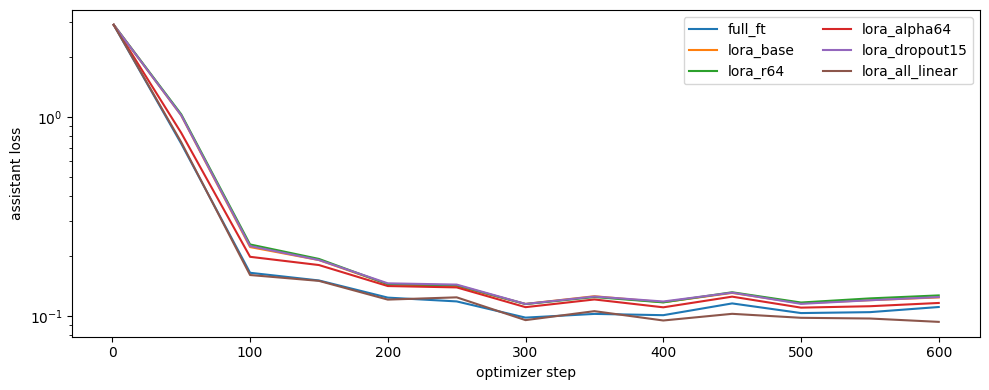

In [8]:
plt.figure(figsize=(10, 4))
for name in names[1:]:
    history = pd.DataFrame(json.loads((out / name / "log_history.json").read_text()))
    history = history.dropna(subset=["loss"])
    plt.plot(history["step"], history["loss"], label=name)
plt.xlabel("optimizer step")
plt.yscale("log")
plt.ylabel("assistant loss")
plt.legend(ncol=2)
plt.tight_layout()
plt.savefig(out / "loss.png", dpi=150)
plt.show()

## 5. Влияние параметров LoRA

В таблице 6 приведена разница относительно `lora_base`. Изменение accuracy и macro-F1 измеряется в процентных пунктах.

In [9]:
ablations = quality.loc[names[3:], ["test_accuracy", "test_macro_f1"]].sub(quality.loc["lora_base", ["test_accuracy", "test_macro_f1"]]) * 100
ablations.columns = ["delta accuracy, п.п.", "delta macro-F1, п.п."]
display(Markdown("Таблица 6. Эффект однофакторных изменений LoRA"))
display(ablations.round(3))

best = max(names[2:], key=lambda name: scores[name]["validation"]["accuracy"])
print("лучшая LoRA по validation:", best)
print("её test accuracy:", round(scores[best]["test"]["accuracy"], 5))

Таблица 6. Эффект однофакторных изменений LoRA

,"delta accuracy, п.п.","delta macro-F1, п.п."
run,,
lora_r64,-0.079,-0.077
lora_alpha64,0.355,0.355
lora_dropout15,0.000,0.004
lora_all_linear,1.895,1.908


лучшая LoRA по validation: lora_all_linear
её test accuracy: 0.93816


### r: 16 → 64

Test accuracy: 91.92% → 91.84%, изменение -0.079 п.п.
Обучаемых параметров стало в четыре раза больше, а качество не улучшилось. При этом alpha оставлен равным 32, поэтому масштаб alpha/r снизился с 2 до 0.5. Здесь измерен эффект смены r при фиксированном alpha; отдельно от изменения масштаба ёмкость адаптера не изолирована.

### alpha: 32 → 64

Test accuracy: 91.92% → 92.28%, изменение +0.355 п.п.
Число обучаемых параметров не меняется, но масштаб alpha/r растёт с 2 до 4. В этом запуске усиление вклада адаптера дало небольшой положительный эффект по качеству при той же размерности.

### dropout: 0.05 → 0.15

Test accuracy: 91.92% → 91.92%, изменение +0.000 п.п.
Размер адаптера не меняется. Более сильный dropout увеличивает регуляризацию, однако здесь доля правильных ответов осталась прежней. На одной эпохе полезного эффекта от этого изменения не обнаружено.

### target_modules: q/v → all-linear

Test accuracy: 91.92% → 93.82%, изменение +1.895 п.п.
Адаптеры добавлены также в k_proj, o_proj и линейные слои MLP. Это дало самый заметный прирост качества среди четырёх изменений, но увеличило число обучаемых параметров и время обучения. Выходной lm_head в all-linear не входит.

Для небольших отличий полезно проверить разброс на самом тесте. Ниже — парный bootstrap разницы accuracy:
одни и те же индексы новостей пересэмплируются для обеих моделей. Интервал описывает неопределённость на этом наборе
примеров, но не заменяет повторные обучения с другими seed.

In [10]:
predictions = {name: pd.read_csv(out / name / "test_predictions.csv") for name in names}
rng = np.random.default_rng(42)
intervals = []
comparisons = [(name, "lora_base") for name in ["full_ft", *names[3:]]]
comparisons.append((best, "full_ft"))
for name, reference_name in comparisons:
    reference = predictions[reference_name]
    frame = predictions[name]
    assert frame["id"].equals(reference["id"])
    diff = (frame["prediction"] == frame["label"]).to_numpy().astype(float) - (reference["prediction"] == reference["label"]).to_numpy()
    draws = [diff[rng.integers(0, len(diff), len(diff))].mean() * 100 for _ in range(2000)]
    low, high = np.quantile(draws, [0.025, 0.975])
    intervals.append({"comparison": f"{name} - {reference_name}", "delta accuracy, п.п.": diff.mean() * 100,
                      "95% low": low, "95% high": high})
display(Markdown("Таблица 7. Парный bootstrap разницы accuracy"))
display(pd.DataFrame(intervals).set_index("comparison").round(3))

Таблица 7. Парный bootstrap разницы accuracy

,"delta accuracy, п.п.",95% low,95% high
comparison,,,
full_ft - lora_base,0.882,0.487,1.263
lora_r64 - lora_base,-0.079,-0.276,0.118
lora_alpha64 - lora_base,0.355,0.092,0.618
lora_dropout15 - lora_base,0.000,-0.132,0.132
lora_all_linear - lora_base,1.895,1.461,2.329
lora_all_linear - full_ft,1.013,0.645,1.368


На фиксированном тесте интервалы для `r=64` и увеличенного dropout включают ноль.
Для alpha=64 прирост невелик: +0.355 п.п., парный 95% интервал от +0.092 до +0.618 п.п.
У all-linear выигрыш относительно Full FT составляет +1.013 п.п., интервал от +0.645 до +1.368 п.п.
Это подтверждает различие на данном тесте, но устойчивость к смене seed обучения остаётся непроверенной.

## 6. Ручная оценка на десяти общих примерах

Примеры выбраны до получения предсказаний: первые 3 World, 3 Sports, 2 Business и 2 Sci/Tech из test.
Во всех трёх основных моделях использованы те же новости и тот же промпт. В таблице 8 показана полная
greedy-генерация: проверяется не только правильный класс, но и соблюдение формата ответа одной цифрой.
К основным трём моделям добавлен лучший LoRA-вариант, выбранный по validation.

In [11]:
manual_names = list(dict.fromkeys(["base", "full_ft", "lora_base", best]))
manual = {name: pd.DataFrame(json.loads((out / name / "manual.json").read_text())).set_index("id")
          for name in manual_names}
common = manual["base"][["text", "label", "expected"]].copy()
for name, frame in manual.items():
    common[name] = frame["answer"]
display(Markdown("Таблица 8. Одинаковые десять запросов к основным моделям и лучшей LoRA"))
display(common[["expected", *manual_names]])
common.to_csv(out / "manual_comparison.csv")

for index, row in common.iterrows():
    display(Markdown(f"**#{index}, {classes[row['label']]}**\n\n{row['text']}\n\n"
                     f"Base: `{row['base']}`; Full FT: `{row['full_ft']}`; LoRA q/v: `{row['lora_base']}`; "
                     f"LoRA {best}: `{row[best]}`."))

Таблица 8. Одинаковые десять запросов к основным моделям и лучшей LoRA

,expected,base,full_ft,lora_base,lora_all_linear
id,,,,,
32,1,1,1,1,1
33,1,1,1,1,1
34,1,1,1,1,1
26,2,1,2,2,2
27,2,1,2,2,2
28,2,1,2,2,2
0,3,1,3,3,3
41,3,1,3,3,3
1,4,4,4,4,4


**#32, World**

Sister of man who died in Vancouver police custody slams chief (Canadian Press) Canadian Press - VANCOUVER (CP) - The sister of a man who died after a violent confrontation with police has demanded the city's chief constable resign for defending the officer involved.

Base: `1`; Full FT: `1`; LoRA q/v: `1`; LoRA lora_all_linear: `1`.

**#33, World**

Man Sought  #36;50M From McGreevey, Aides Say (AP) AP - The man who claims Gov. James E. McGreevey sexually harassed him was pushing for a cash settlement of up to  #36;50 million before the governor decided to announce that he was gay and had an extramarital affair, sources told The Associated Press.

Base: `1`; Full FT: `1`; LoRA q/v: `1`; LoRA lora_all_linear: `1`.

**#34, World**

Explosions Echo Throughout Najaf NAJAF, Iraq - Explosions and gunfire rattled through the city of Najaf as U.S. troops in armored vehicles and tanks rolled back into the streets here Sunday, a day after the collapse of talks - and with them a temporary cease-fire - intended to end the fighting in this holy city...

Base: `1`; Full FT: `1`; LoRA q/v: `1`; LoRA lora_all_linear: `1`.

**#26, Sports**

Giddy Phelps Touches Gold for First Time Michael Phelps won the gold medal in the 400 individual medley and set a world record in a time of 4 minutes 8.26 seconds.

Base: `1`; Full FT: `2`; LoRA q/v: `2`; LoRA lora_all_linear: `2`.

... (2 outputs left out)

**#0, Business**

Fears for T N pension after talks Unions representing workers at Turner   Newall say they are 'disappointed' after talks with stricken parent firm Federal Mogul.

Base: `1`; Full FT: `3`; LoRA q/v: `3`; LoRA lora_all_linear: `3`.

**#41, Business**

Retailers Vie for Back-To-School Buyers (Reuters) Reuters - Apparel retailers are hoping their\back-to-school fashions will make the grade among\style-conscious teens and young adults this fall, but it could\be a tough sell, with students and parents keeping a tighter\hold on their wallets.

Base: `1`; Full FT: `3`; LoRA q/v: `3`; LoRA lora_all_linear: `3`.

**#1, Sci/Tech**

The Race is On: Second Private Team Sets Launch Date for Human Spaceflight (SPACE.com) SPACE.com - TORONTO, Canada -- A second\team of rocketeers competing for the  #36;10 million Ansari X Prize, a contest for\privately funded suborbital space flight, has officially announced the first\launch date for its manned rocket.

Base: `4`; Full FT: `4`; LoRA q/v: `4`; LoRA lora_all_linear: `4`.

**#2, Sci/Tech**

Ky. Company Wins Grant to Study Peptides (AP) AP - A company founded by a chemistry researcher at the University of Louisville won a grant to develop a method of producing better peptides, which are short chains of amino acids, the building blocks of proteins.

Base: `4`; Full FT: `4`; LoRA q/v: `4`; LoRA lora_all_linear: `4`.

При ручной проверке правильный класс и формат совпали у base в 5 из 10 случаев,
у Full FT — в 10, у базовой LoRA — в 10, у `lora_all_linear` — в 10.

Новости #32–34 относятся к World: полиция, политический скандал и военные действия. Упоминание 50 млн долларов в #33
не делает основную тему бизнесом. Новости #26–28 — спортивные результаты и игроки; именно здесь у base виден
сдвиг к первой метке. В #0 и #41 обсуждаются пенсионные обязательства компании и продажи ретейлеров — это Business.
Наконец, #1 про частный космический полёт и #2 про исследования пептидов относятся к Sci/Tech, несмотря на упоминание
компаний и гранта.

Десять примеров показывают конкретные различия поведения, но не заменяют метрики на всех 7 600 новостях.

Для выбранной задачи базовая LoRA даёт изменение accuracy -0.882 п.п. относительно Full FT,
при сокращении числа обучаемых параметров в 708.4 раза.
Память при этом сокращается гораздо слабее: исходные веса модели и активации по-прежнему нужны.
Это объясняет, почему экономия обучаемых параметров не превращается в такое же ускорение или уменьшение GPU-памяти.

## 7. Выводы и ограничения

Full FT обучает 1,543,714,304 параметров, базовая LoRA — 2,179,072
(0.141% параметров модели с адаптерами).
Full FT занял 242.4 с и 27.53 GiB peak allocated,
LoRA — 216.1 с и 15.62 GiB.

Среди LoRA-вариантов validation выбрал `lora_all_linear`: test accuracy 93.82%,
macro-F1 0.9381.

Для этой задачи предпочтительнее LoRA с `all-linear`, если основной критерий — качество:
accuracy 93.82% против 92.80% у Full FT,
а обучаемых параметров в 83.6 раза меньше.
Пиковая allocated-память также ниже: 22.52 против 27.53 GiB.
При этом обучение оказалось медленнее: 358.6 против 242.4 с.
Адаптеры добавляют отдельные матричные операции, поэтому маленькое число обучаемых весов само по себе
не гарантирует ускорения. Детальная профилировка этого различия не проводилась.

Если важнее минимальная память и время одного запуска, базовая LoRA q/v практичнее:
15.62 GiB, 216.1 с и 91.92% accuracy. Full FT здесь занял промежуточное положение по качеству и времени,
но потребовал больше памяти и обновления всех весов.

Границы вывода: одна задача, одна эпоха, один seed и 20 000 train. Небольшие отличия не дают основания объявлять один
гиперпараметр универсально лучшим. Обе основные метрики оценивают классификацию новостей; сохранение общих навыков
и ответы на других задачах здесь не проверялись. Датасет публичный и мог встречаться в предобучении Qwen,
поэтому test означает отсутствие пересечений с нашим дообучением, а не гарантированно новые для модели данные.

## 8. Воспроизведение

Запускать из `hw4_lora` на CUDA GPU. Использованы PyTorch 2.6.0+cu118 и зависимости из `requirements.txt`.

```bash
python -m pip install torch==2.6.0 --index-url https://download.pytorch.org/whl/cu118
python -m pip install -r requirements.txt
python experiment.py check
python experiment.py all
```

`all` готовит фиксированные данные и последовательно запускает семь конфигураций в отдельных процессах.
Успешный запуск пропускается, если его `summary.json` уже есть. Для полного повторения следует использовать
новую рабочую папку только с `experiment.py` и `requirements.txt`. Скрипт использует зафиксированные ревизии модели
и датасета. Полученный split hash должен совпасть с опубликованным `data_manifest.json`.

Один эксперимент можно запустить командой `python experiment.py lora_r64`.
В `outputs/<run>/` находятся исходные метрики, история loss и все предсказания для проверки расчётов.
Веса сохраняются локально в `checkpoints/` и исключены из Git; подготовленные Arrow-данные в `data/` также не публикуются.
Для чтения этого отчёта повторно обучать модели не требуется: все ячейки используют сохранённые артефакты.

Источники: [AG News](https://huggingface.co/datasets/fancyzhx/ag_news),
[Qwen2.5-1.5B-Instruct](https://huggingface.co/Qwen/Qwen2.5-1.5B-Instruct),
[PEFT LoraConfig](https://huggingface.co/docs/peft/v0.17.0/en/package_reference/lora).